In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# Create comparison results

results = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest n_estimators=100",
        "Random Forest max_depth=10",
        "Random Forest min_samples_split=5",
        "Random Forest max_features=log2"
    ],
    "Accuracy": [
        0.952941,
        0.952941,
        0.952941,
        0.958824,
        0.952941
    ],
    "Precision": [
        0.954270,
        0.954270,
        0.953361,
        0.959500,
        0.954270
    ],
    "Recall": [
        0.952941,
        0.952941,
        0.952941,
        0.958824,
        0.952941
    ],
    "F1-Score": [
        0.953012,
        0.953012,
        0.952951,
        0.958844,
        0.953012
    ],
    "Training Time": [
        0.266764,
        0.266764,
        0.286397,
        0.193054,
        0.223550
    ]
})

display(results)

,Model,Accuracy,Precision,Recall,F1-Score,Training Time
0,Random Forest Baseline,0.952941,0.954270,0.952941,0.953012,0.266764
1,Random Forest n_estimators=100,0.952941,0.954270,0.952941,0.953012,0.266764
2,Random Forest max_depth=10,0.952941,0.953361,0.952941,0.952951,0.286397
3,Random Forest min_samples_split=5,0.958824,0.959500,0.958824,0.958844,0.193054
4,Random Forest max_features=log2,0.952941,0.954270,0.952941,0.953012,0.223550


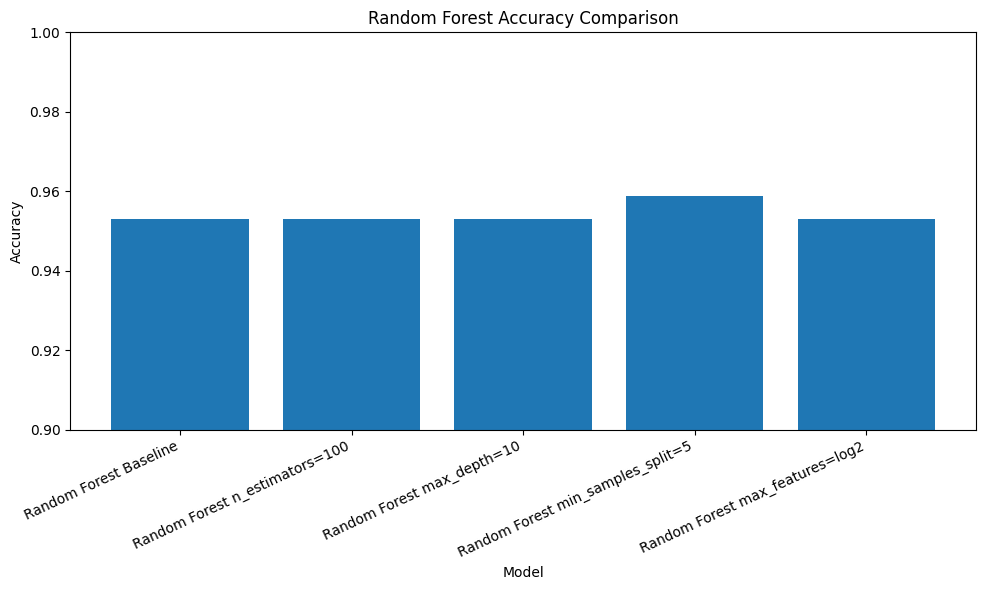

In [3]:
# Accuracy Comparison

plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["Accuracy"])

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Random Forest Accuracy Comparison")
plt.xticks(rotation=25, ha="right")
plt.ylim(0.90, 1.00)

plt.tight_layout()
plt.show()

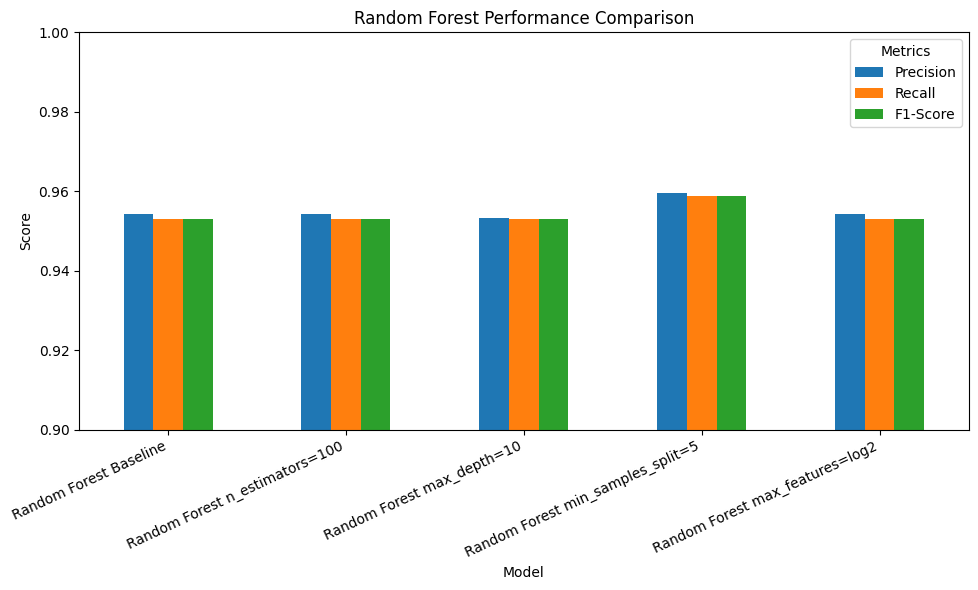

In [4]:
# Precision, Recall, and F1-Score Comparison

metrics = ["Precision", "Recall", "F1-Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Random Forest Performance Comparison")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Metrics")

plt.tight_layout()
plt.show()

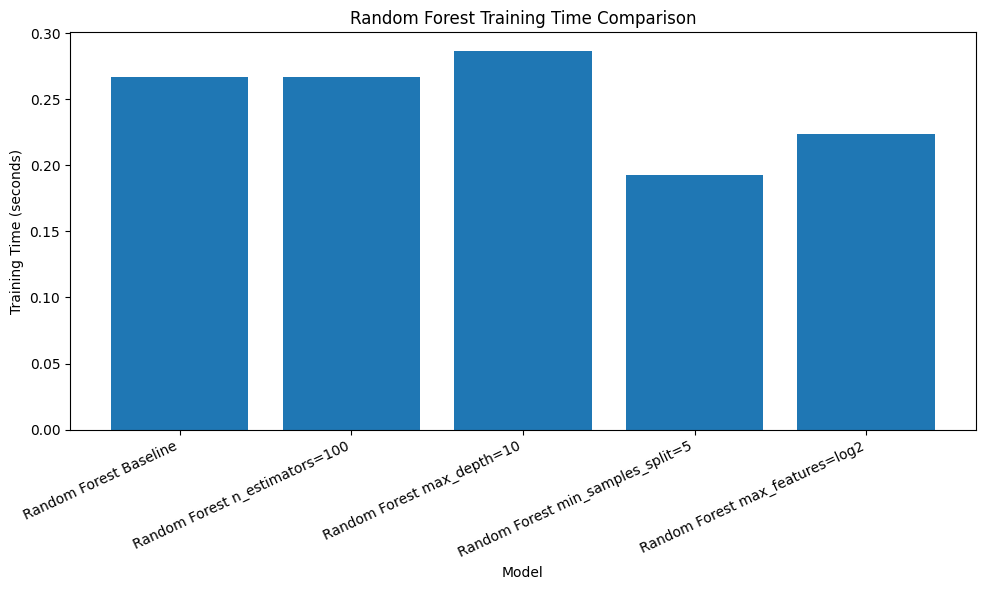

In [5]:
# Training Time Comparison

plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["Training Time"])

plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.title("Random Forest Training Time Comparison")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [6]:
# Find the best model based on F1-Score

best_model = results.loc[results["F1-Score"].idxmax()]

print("Best Model:")
print(best_model["Model"])

print("\nBest Performance:")
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])

Best Model:
Random Forest min_samples_split=5

Best Performance:
Accuracy: 0.958824
Precision: 0.9595
Recall: 0.958824
F1-Score: 0.958844


In [7]:
# Save comparison results

results.to_csv("random_forest_comparison_results.csv", index=False)

print("Comparison results saved successfully.")

Comparison results saved successfully.
